In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [3]:
data = pd.read_csv("winequality-red.csv",sep=";")
print(data.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [4]:
X = data.drop("quality", axis=1)
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [5]:
# Scale the input data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# Try different MLP architectures
models = {
    "1 Hidden Layer (10 neurons)": (10,),
    "1 Hidden Layer (20 neurons)": (20,),
    "2 Hidden Layers (20,10)": (20, 10),
    "2 Hidden Layers (30,15)": (30, 15),
    "3 Hidden Layers (30,20,10)": (30, 20, 10)
}

1 Hidden Layer (10 neurons) : 56.56 %


/home/student/.local/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


1 Hidden Layer (20 neurons) : 57.5 %


/home/student/.local/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


2 Hidden Layers (20,10) : 58.75 %


/home/student/.local/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


2 Hidden Layers (30,15) : 62.5 %
3 Hidden Layers (30,20,10) : 61.25 %


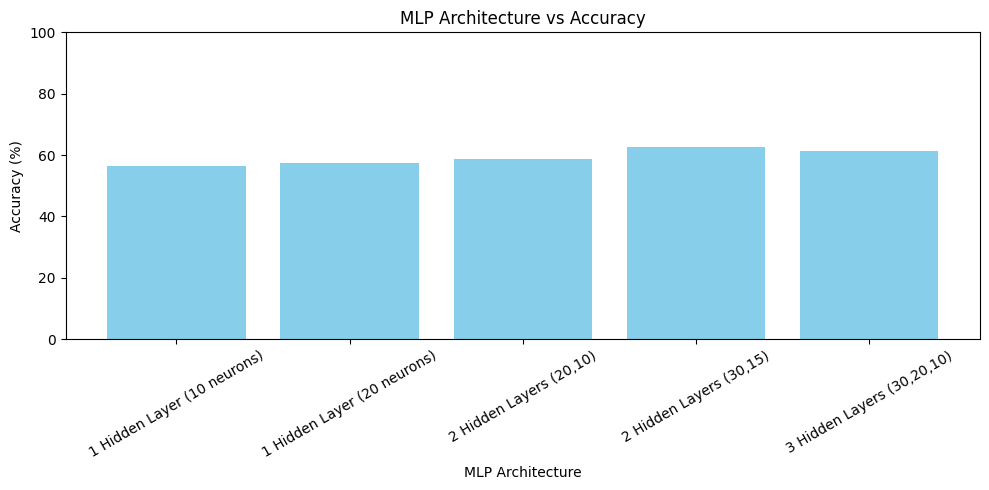

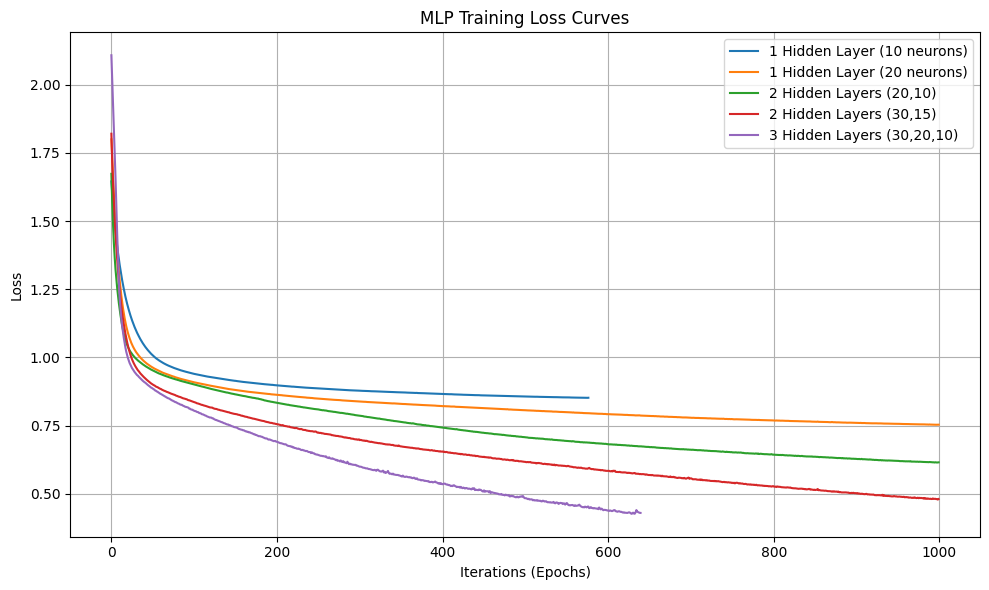

In [9]:
import matplotlib.pyplot as plt

names = []
accuracies = []
loss_curves = {}

for name, layers in models.items():

    model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Predictions and accuracy
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    names.append(name)
    accuracies.append(accuracy * 100)

    # Save loss curve
    loss_curves[name] = model.loss_curve_

    print(name, ":", round(accuracy * 100, 2), "%")


# -----------------------------
# Accuracy graph
# -----------------------------
plt.figure(figsize=(10, 5))

plt.bar(names, accuracies, color="skyblue")

plt.xlabel("MLP Architecture")
plt.ylabel("Accuracy (%)")
plt.title("MLP Architecture vs Accuracy")

plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# -----------------------------
# Loss curves
# -----------------------------
plt.figure(figsize=(10, 6))

for name, loss in loss_curves.items():
    plt.plot(loss, label=name)

plt.xlabel("Iterations (Epochs)")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
